In [62]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/Demographics_age_sex.xlsx
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545616858-3A749CBC-3FEB-4D35-820E-E45C3E5B9B6A.wav
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545841227-5C77713A-66F1-49D0-BC8A-702C152E668D.wav
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545753014-C68926CC-AB91-49AF-90A6-BB5C434283DB.wav
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545622719-52C23861-6E0D-41E0-A3D8-9358C28C019B.wav
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545643618-82A143AC-B643-4273-A923-C42A83AEEC5F.wav
/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/PD_AH/PD_AH/AH_545789674-53885025-35F1-48C1-9826-BAAEB8BEAF58.wav
/kaggle/input/datasets/mohitraajdeev/pa

In [63]:
# Parkinson's Disease Detection from Speech
# Dataset: Parkinson's Disease and Healthy Controls
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [64]:
data_path = "/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls"

print(data_path)

/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls


In [65]:
for item in os.listdir(data_path):
    print(item)

PD_AH
Demographics_age_sex.xlsx
HC_AH


In [66]:
excel_path = os.path.join(data_path, "Demographics_age_sex.xlsx")

print(excel_path)
print(os.path.exists(excel_path))

/kaggle/input/datasets/mohitraajdeev/parkinsons-disease-and-healthy-controls/Demographics_age_sex.xlsx
True


In [67]:
excel_file = pd.ExcelFile(excel_path)

print("Sheets available:")
for i, sheet in enumerate(excel_file.sheet_names, start=1):
    print(f"{i}. {sheet}")

Sheets available:
1. Parselmouth
2. LPC_means
3. LAR_means
4. Cep_means
5. MFCC_means
6. LPC_vars
7. LAR_vars
8. Cep_vars
9. MFCC_vars


In [68]:
# Load all sheets into separate DataFrames

sheets = {}

for sheet_name in excel_file.sheet_names:
    sheets[sheet_name] = pd.read_excel(excel_path, sheet_name=sheet_name)

print("All sheets loaded successfully!")

All sheets loaded successfully!


In [69]:
# Check the number of rows and columns in every sheet

for name, df in sheets.items():
    print(f"{name:15} → {df.shape}")

Parselmouth     → (81, 4)
LPC_means       → (81, 12)
LAR_means       → (81, 12)
Cep_means       → (81, 12)
MFCC_means      → (81, 12)
LPC_vars        → (81, 12)
LAR_vars        → (81, 12)
Cep_vars        → (81, 12)
MFCC_vars       → (81, 12)


In [70]:
# Display the columns of every sheet

for name, df in sheets.items():
    print(f"\n{'='*50}")
    print(name)
    print(df.columns.tolist())


Parselmouth
['Sample ID', 'Label', 'Age', 'Sex']

LPC_means
['Sample', 'LPC1', 'LPC2', 'LPC3', 'LPC4', 'LPC5', 'LPC6', 'LPC7', 'LPC8', 'LPC9', 'LPC10', 'Label']

LAR_means
['Sample', 'LAR1', 'LAR2', 'LAR3', 'LAR4', 'LAR5', 'LAR6', 'LAR7', 'LAR8', 'LAR9', 'LAR10', 'Label']

Cep_means
['Sample', 'Cep1', 'Cep2', 'Cep3', 'Cep4', 'Cep5', 'Cep6', 'Cep7', 'Cep8', 'Cep9', 'Cep10', 'Label']

MFCC_means
['Sample', 'MFCC1', 'MFCC2', 'MFCC3', 'MFCC4', 'MFCC5', 'MFCC6', 'MFCC7', 'MFCC8', 'MFCC9', 'MFCC10', 'Label']

LPC_vars
['Sample', 'LPC1', 'LPC2', 'LPC3', 'LPC4', 'LPC5', 'LPC6', 'LPC7', 'LPC8', 'LPC9', 'LPC10', 'Label']

LAR_vars
['Sample', 'LAR1', 'LAR2', 'LAR3', 'LAR4', 'LAR5', 'LAR6', 'LAR7', 'LAR8', 'LAR9', 'LAR10', 'Label']

Cep_vars
['Sample', 'Cep1', 'Cep2', 'Cep3', 'Cep4', 'Cep5', 'Cep6', 'Cep7', 'Cep8', 'Cep9', 'Cep10', 'Label']

MFCC_vars
['Sample', 'MFCC1', 'MFCC2', 'MFCC3', 'MFCC4', 'MFCC5', 'MFCC6', 'MFCC7', 'MFCC8', 'MFCC9', 'MFCC10', 'Label']


In [71]:
# Preview the first 5 rows of every sheet

for name, df in sheets.items():
    print(f"\n{'='*60}")
    print(f"  {name}")
    print(f"{'='*60}")
    display(df.head())


  Parselmouth


,Sample ID,Label,Age,Sex
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,HC,69.0,M
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,HC,43.0,M
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,HC,18.0,F
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,HC,28.0,M
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,HC,68.0,M



  LPC_means


,Sample,LPC1,LPC2,LPC3,LPC4,LPC5,LPC6,LPC7,LPC8,LPC9,LPC10,Label
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,1.569877,-0.983969,-0.091904,0.041568,0.191788,-0.288774,0.322170,-0.598547,0.407556,-0.107863,HC
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,1.941508,-1.604020,0.596933,-0.203145,0.049751,0.149339,-0.181571,-0.076214,0.181712,-0.080028,HC
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,1.939210,-1.400189,0.267341,-0.117478,0.393466,-0.146857,-0.267388,0.218443,0.052065,-0.110188,HC
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,1.742062,-1.111498,0.209142,-0.208665,0.172042,0.230845,-0.125670,-0.521256,0.695029,-0.249518,HC
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,1.370398,-0.725562,0.058470,-0.669424,0.762271,-0.077152,-0.350492,-0.027547,0.154888,-0.025133,HC



  LAR_means


,Sample,LAR1,LAR2,LAR3,LAR4,LAR5,LAR6,LAR7,LAR8,LAR9,LAR10,Label
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,-2.123660,2.611158,-0.393556,-0.094781,0.567397,0.782027,0.148450,0.278406,-0.483335,0.218335,HC
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,-2.518993,2.496645,-0.840103,0.255390,0.017946,0.266291,0.145758,-0.200821,-0.041717,0.161747,HC
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,-2.715108,2.334247,-0.946445,-0.107626,0.066838,0.356135,-0.120852,-0.069662,0.328265,0.222140,HC
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,-2.491609,2.191687,-0.391480,0.077111,-0.330893,0.194991,0.278090,-0.442716,-0.552145,0.515340,HC
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,-1.851492,2.215288,-0.014241,0.131671,-0.482659,1.113443,0.465544,-0.300798,-0.242269,0.050628,HC


... (8 outputs left out)


  Cep_vars


,Sample,Cep1,Cep2,Cep3,Cep4,Cep5,Cep6,Cep7,Cep8,Cep9,Cep10,Label
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,0.017127,0.006500,0.015470,0.009457,0.003669,0.003850,0.007161,0.005827,0.001147,0.002577,HC
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,0.055998,0.021600,0.026646,0.034568,0.018671,0.005877,0.007571,0.008997,0.001723,0.002501,HC
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,0.073417,0.037979,0.009990,0.019997,0.003989,0.011363,0.004133,0.001805,0.001118,0.001234,HC
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,0.022939,0.009730,0.007749,0.003729,0.002405,0.002080,0.004287,0.003234,0.001041,0.001659,HC
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,0.024344,0.028752,0.017603,0.017567,0.002334,0.002900,0.003359,0.004246,0.004181,0.001876,HC



  MFCC_vars


,Sample,MFCC1,MFCC2,MFCC3,MFCC4,MFCC5,MFCC6,MFCC7,MFCC8,MFCC9,MFCC10,Label
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,0.038758,0.022063,0.017446,0.040128,0.025198,0.075028,0.026978,0.022016,0.049959,0.016487,HC
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,0.376447,0.043026,0.113414,0.202135,0.076834,0.177133,0.106460,0.058875,0.070278,0.057396,HC
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,0.181835,0.065868,0.081565,0.028965,0.032045,0.029428,0.045059,0.037183,0.020112,0.016252,HC
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,0.101589,0.012878,0.019212,0.015828,0.023448,0.048831,0.026585,0.024423,0.011855,0.016314,HC
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,0.505912,0.031619,0.023236,0.051445,0.032242,0.031627,0.053048,0.027289,0.119403,0.046914,HC


In [72]:
# Check whether all sheets contain the same samples

sample_sets = {}

for name, df in sheets.items():
    column = "Sample ID" if name == "Parselmouth" else "Sample"
    sample_sets[name] = set(df[column])

reference_samples = sample_sets["Parselmouth"]

for name, samples in sample_sets.items():
    print(
        f"{name:15} → "
        f"{len(samples)} samples | "
        f"Same as Parselmouth: {samples == reference_samples}"
    )

Parselmouth     → 81 samples | Same as Parselmouth: True
LPC_means       → 81 samples | Same as Parselmouth: True
LAR_means       → 81 samples | Same as Parselmouth: True
Cep_means       → 81 samples | Same as Parselmouth: True
MFCC_means      → 81 samples | Same as Parselmouth: True
LPC_vars        → 81 samples | Same as Parselmouth: True
LAR_vars        → 81 samples | Same as Parselmouth: True
Cep_vars        → 81 samples | Same as Parselmouth: True
MFCC_vars       → 81 samples | Same as Parselmouth: True


In [73]:
# Check label distribution in every sheet

for name, df in sheets.items():
    print(f"\n{name}")
    print(df["Label"].value_counts())


Parselmouth
Label
HC      41
PwPD    40
Name: count, dtype: int64

LPC_means
Label
HC      41
PwPD    40
Name: count, dtype: int64

LAR_means
Label
HC      41
PwPD    40
Name: count, dtype: int64

Cep_means
Label
HC      41
PwPD    40
Name: count, dtype: int64

MFCC_means
Label
HC      41
PwPD    40
Name: count, dtype: int64

LPC_vars
Label
HC      41
PwPD    40
Name: count, dtype: int64

LAR_vars
Label
HC      41
PwPD    40
Name: count, dtype: int64

Cep_vars
Label
HC      41
PwPD    40
Name: count, dtype: int64

MFCC_vars
Label
HC      41
PwPD    40
Name: count, dtype: int64


In [74]:
# Standardize the ID column name across all sheets

for name, df in sheets.items():
    if name == "Parselmouth":
        df.rename(columns={"Sample ID": "Sample"}, inplace=True)

print("ID column standardized.")

ID column standardized.


In [75]:
# Create the initial master dataset from demographic information

master_df = sheets["Parselmouth"].copy()

print("Initial master dataset shape:", master_df.shape)
display(master_df.head())

Initial master dataset shape: (81, 4)


,Sample,Label,Age,Sex
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,HC,69.0,M
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,HC,43.0,M
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,HC,18.0,F
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,HC,28.0,M
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,HC,68.0,M


In [76]:
# Merge all feature sheets into the master dataset

feature_sheets = [
    "LPC_means",
    "LAR_means",
    "Cep_means",
    "MFCC_means",
    "LPC_vars",
    "LAR_vars",
    "Cep_vars",
    "MFCC_vars"
]

for name in feature_sheets:
    feature_df = sheets[name].drop(columns=["Label"])
    master_df = master_df.merge(
        feature_df,
        on="Sample",
        how="inner"
    )

print("Final master dataset shape:", master_df.shape)

Final master dataset shape: (81, 84)


In [77]:
# Display master dataframe

print("Rows:", master_df.shape[0])
print("Columns:", master_df.shape[1])

display(master_df.head())

Rows: 81
Columns: 84


,Sample,Label,Age,Sex,LPC1_x,LPC2_x,LPC3_x,LPC4_x,LPC5_x,LPC6_x,...,MFCC1_y,MFCC2_y,MFCC3_y,MFCC4_y,MFCC5_y,MFCC6_y,MFCC7_y,MFCC8_y,MFCC9_y,MFCC10_y
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,HC,69.0,M,1.569877,-0.983969,-0.091904,0.041568,0.191788,-0.288774,...,0.038758,0.022063,0.017446,0.040128,0.025198,0.075028,0.026978,0.022016,0.049959,0.016487
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,HC,43.0,M,1.941508,-1.604020,0.596933,-0.203145,0.049751,0.149339,...,0.376447,0.043026,0.113414,0.202135,0.076834,0.177133,0.106460,0.058875,0.070278,0.057396
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,HC,18.0,F,1.939210,-1.400189,0.267341,-0.117478,0.393466,-0.146857,...,0.181835,0.065868,0.081565,0.028965,0.032045,0.029428,0.045059,0.037183,0.020112,0.016252
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,HC,28.0,M,1.742062,-1.111498,0.209142,-0.208665,0.172042,0.230845,...,0.101589,0.012878,0.019212,0.015828,0.023448,0.048831,0.026585,0.024423,0.011855,0.016314
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,HC,68.0,M,1.370398,-0.725562,0.058470,-0.669424,0.762271,-0.077152,...,0.505912,0.031619,0.023236,0.051445,0.032242,0.031627,0.053048,0.027289,0.119403,0.046914


In [78]:
# Display columns in master dataframe

for i, column in enumerate(master_df.columns, start=1):
    print(f"{i:2}. {column}")

 1. Sample
 2. Label
 3. Age
 4. Sex
 5. LPC1_x
 6. LPC2_x
 7. LPC3_x
 8. LPC4_x
 9. LPC5_x
10. LPC6_x
11. LPC7_x
12. LPC8_x
13. LPC9_x
14. LPC10_x
15. LAR1_x
16. LAR2_x
17. LAR3_x
18. LAR4_x
19. LAR5_x
20. LAR6_x
21. LAR7_x
22. LAR8_x
23. LAR9_x
24. LAR10_x
25. Cep1_x
26. Cep2_x
27. Cep3_x
28. Cep4_x
29. Cep5_x
30. Cep6_x
31. Cep7_x
32. Cep8_x
33. Cep9_x
34. Cep10_x
35. MFCC1_x
36. MFCC2_x
37. MFCC3_x
38. MFCC4_x
39. MFCC5_x
40. MFCC6_x
41. MFCC7_x
42. MFCC8_x
43. MFCC9_x
44. MFCC10_x
45. LPC1_y
46. LPC2_y
47. LPC3_y
48. LPC4_y
49. LPC5_y
50. LPC6_y
51. LPC7_y
52. LPC8_y
53. LPC9_y
54. LPC10_y
55. LAR1_y
56. LAR2_y
57. LAR3_y
58. LAR4_y
59. LAR5_y
60. LAR6_y
61. LAR7_y
62. LAR8_y
63. LAR9_y
64. LAR10_y
65. Cep1_y
66. Cep2_y
67. Cep3_y
68. Cep4_y
69. Cep5_y
70. Cep6_y
71. Cep7_y
72. Cep8_y
73. Cep9_y
74. Cep10_y
75. MFCC1_y
76. MFCC2_y
77. MFCC3_y
78. MFCC4_y
79. MFCC5_y
80. MFCC6_y
81. MFCC7_y
82. MFCC8_y
83. MFCC9_y
84. MFCC10_y


In [79]:
# Rename feature columns to clearly distinguish means and variances

rename_dict = {}

for feature in ["LPC", "LAR", "Cep", "MFCC"]:
    for i in range(1, 11):
        rename_dict[f"{feature}{i}_x"] = f"{feature}{i}_mean"
        rename_dict[f"{feature}{i}_y"] = f"{feature}{i}_var"

master_df.rename(columns=rename_dict, inplace=True)

print("Feature names cleaned successfully!")

Feature names cleaned successfully!


In [80]:
print(master_df.columns.tolist())

['Sample', 'Label', 'Age', 'Sex', 'LPC1_mean', 'LPC2_mean', 'LPC3_mean', 'LPC4_mean', 'LPC5_mean', 'LPC6_mean', 'LPC7_mean', 'LPC8_mean', 'LPC9_mean', 'LPC10_mean', 'LAR1_mean', 'LAR2_mean', 'LAR3_mean', 'LAR4_mean', 'LAR5_mean', 'LAR6_mean', 'LAR7_mean', 'LAR8_mean', 'LAR9_mean', 'LAR10_mean', 'Cep1_mean', 'Cep2_mean', 'Cep3_mean', 'Cep4_mean', 'Cep5_mean', 'Cep6_mean', 'Cep7_mean', 'Cep8_mean', 'Cep9_mean', 'Cep10_mean', 'MFCC1_mean', 'MFCC2_mean', 'MFCC3_mean', 'MFCC4_mean', 'MFCC5_mean', 'MFCC6_mean', 'MFCC7_mean', 'MFCC8_mean', 'MFCC9_mean', 'MFCC10_mean', 'LPC1_var', 'LPC2_var', 'LPC3_var', 'LPC4_var', 'LPC5_var', 'LPC6_var', 'LPC7_var', 'LPC8_var', 'LPC9_var', 'LPC10_var', 'LAR1_var', 'LAR2_var', 'LAR3_var', 'LAR4_var', 'LAR5_var', 'LAR6_var', 'LAR7_var', 'LAR8_var', 'LAR9_var', 'LAR10_var', 'Cep1_var', 'Cep2_var', 'Cep3_var', 'Cep4_var', 'Cep5_var', 'Cep6_var', 'Cep7_var', 'Cep8_var', 'Cep9_var', 'Cep10_var', 'MFCC1_var', 'MFCC2_var', 'MFCC3_var', 'MFCC4_var', 'MFCC5_var', 'MFC

In [81]:
print("Dataset shape:", master_df.shape)
print("\nData types:")
print(master_df.dtypes)

Dataset shape: (81, 84)

Data types:
Sample         object
Label          object
Age           float64
Sex            object
LPC1_mean     float64
               ...   
MFCC6_var     float64
MFCC7_var     float64
MFCC8_var     float64
MFCC9_var     float64
MFCC10_var    float64
Length: 84, dtype: object


In [82]:
# check missing values

print("\nMissing values:")
print(master_df.isnull().sum())


Missing values:
Sample        0
Label         0
Age           0
Sex           0
LPC1_mean     0
             ..
MFCC6_var     0
MFCC7_var     0
MFCC8_var     0
MFCC9_var     0
MFCC10_var    0
Length: 84, dtype: int64


In [83]:
# Check duplicates

print("\nDuplicate rows:", master_df.duplicated().sum())
print("Duplicate Sample IDs:", master_df["Sample"].duplicated().sum())


Duplicate rows: 0
Duplicate Sample IDs: 0


In [84]:
# Check numerical validity

numeric_cols = master_df.select_dtypes(include=np.number).columns

print("Infinite values:")
print(np.isinf(master_df[numeric_cols]).sum().sum())

Infinite values:
0


In [85]:
# Complete data-quality summary

print("DATA QUALITY SUMMARY")

print(f"Dataset shape       : {master_df.shape}")
print(f"Missing values      : {master_df.isnull().sum().sum()}")
print(f"Duplicate rows      : {master_df.duplicated().sum()}")
print(f"Duplicate Sample IDs: {master_df['Sample'].duplicated().sum()}")

numeric_cols = master_df.select_dtypes(include=np.number).columns
print(f"Infinite values     : {np.isinf(master_df[numeric_cols]).sum().sum()}")

print("\nLabel distribution:")
print(master_df["Label"].value_counts())

print("\nData types:")
print(master_df.dtypes.value_counts())

DATA QUALITY SUMMARY
Dataset shape       : (81, 84)
Missing values      : 0
Duplicate rows      : 0
Duplicate Sample IDs: 0
Infinite values     : 0

Label distribution:
Label
HC      41
PwPD    40
Name: count, dtype: int64

Data types:
float64    81
object      3
Name: count, dtype: int64


***Exploratory data analysis***

In [86]:
# Class distribution

label_counts = master_df["Label"].value_counts()
print("Class Distribution:")
print(label_counts)

label_percent = master_df["Label"].value_counts(normalize=True) * 100
print("\nClass Percentage:")
print(label_percent.round(2))

Class Distribution:
Label
HC      41
PwPD    40
Name: count, dtype: int64

Class Percentage:
Label
HC      50.62
PwPD    49.38
Name: proportion, dtype: float64


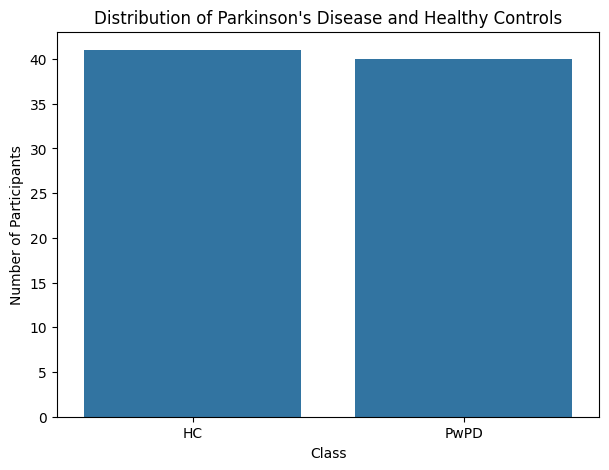

In [87]:
plt.figure(figsize=(7, 5))

sns.countplot(data=master_df, x="Label")

plt.title("Distribution of Parkinson's Disease and Healthy Controls")
plt.xlabel("Class")
plt.ylabel("Number of Participants")

plt.show()

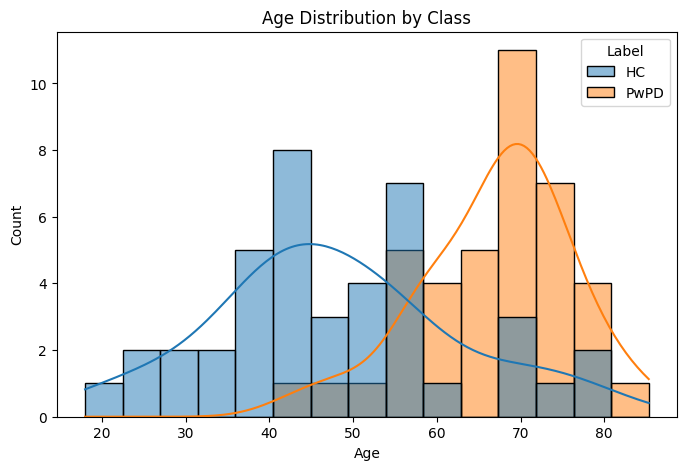

In [88]:
# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=master_df,
    x="Age",
    hue="Label",
    bins=15,
    kde=True
)

plt.title("Age Distribution by Class")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

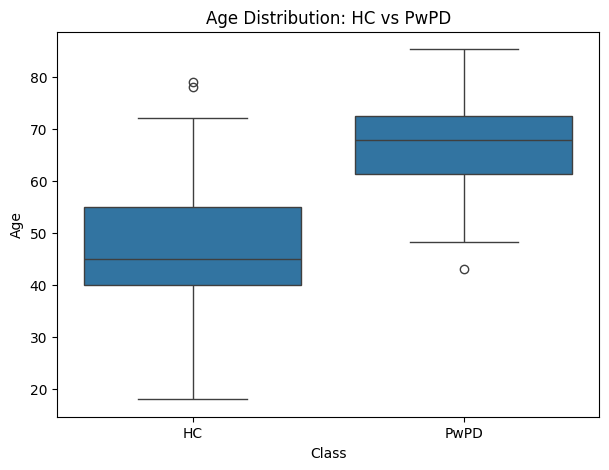

In [89]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=master_df,
    x="Label",
    y="Age"
)

plt.title("Age Distribution: HC vs PwPD")
plt.xlabel("Class")
plt.ylabel("Age")

plt.show()

In [90]:
master_df.groupby("Label")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
HC,41.0,47.731707,14.328336,18.00,40.000,45.000,55.0000,79.00
PwPD,40.0,67.035000,8.982819,43.12,61.365,67.895,72.4175,85.31


In [91]:
# Sex distribution

sex_counts = master_df.groupby(["Label", "Sex"]).size().unstack()

print("Sex distribution by class:")
print(sex_counts)

Sex distribution by class:
Sex     F   M
Label        
HC     25  16
PwPD   19  21


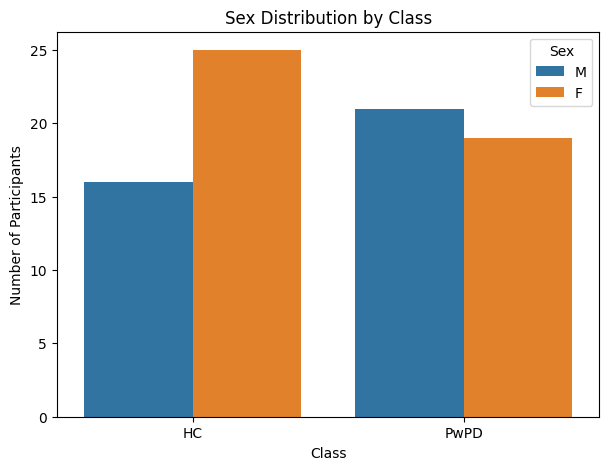

In [92]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=master_df,
    x="Label",
    hue="Sex"
)

plt.title("Sex Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Participants")

plt.show()

In [93]:
# Identify speech feature groups

lpc_features = [col for col in master_df.columns if col.startswith("LPC")]
lar_features = [col for col in master_df.columns if col.startswith("LAR")]
cep_features = [col for col in master_df.columns if col.startswith("Cep")]
mfcc_features = [col for col in master_df.columns if col.startswith("MFCC")]

print("LPC features :", len(lpc_features))
print("LAR features :", len(lar_features))
print("Cep features :", len(cep_features))
print("MFCC features:", len(mfcc_features))
print("Total speech features:", 
      len(lpc_features) + len(lar_features) +
      len(cep_features) + len(mfcc_features))

LPC features : 20
LAR features : 20
Cep features : 20
MFCC features: 20
Total speech features: 80


In [94]:
# Statistical summary of speech features

speech_features = (
    lpc_features +
    lar_features +
    cep_features +
    mfcc_features
)
speech_summary = master_df[speech_features].describe().T

speech_summary

,count,mean,std,min,25%,50%,75%,max
LPC1_mean,81.0,1.594083,0.256121,0.923475,1.428698,1.620231,1.790834,2.044157
LPC2_mean,81.0,-0.999559,0.455513,-1.955843,-1.276864,-1.002650,-0.746939,0.494960
LPC3_mean,81.0,0.105330,0.440579,-0.957053,-0.160625,0.063049,0.309396,1.519694
LPC4_mean,81.0,-0.248627,0.379721,-1.314744,-0.512572,-0.208665,0.041568,0.467297
LPC5_mean,81.0,0.436917,0.321555,-0.252382,0.189548,0.446606,0.665490,1.147827
...,...,...,...,...,...,...,...,...
MFCC6_var,81.0,0.082428,0.065749,0.006807,0.035516,0.065067,0.112672,0.303602
MFCC7_var,81.0,0.077640,0.058848,0.009808,0.033590,0.059496,0.101623,0.285948
MFCC8_var,81.0,0.070417,0.063464,0.006674,0.028349,0.056528,0.089988,0.368150
MFCC9_var,81.0,0.074238,0.063071,0.010808,0.028739,0.055569,0.101336,0.359709


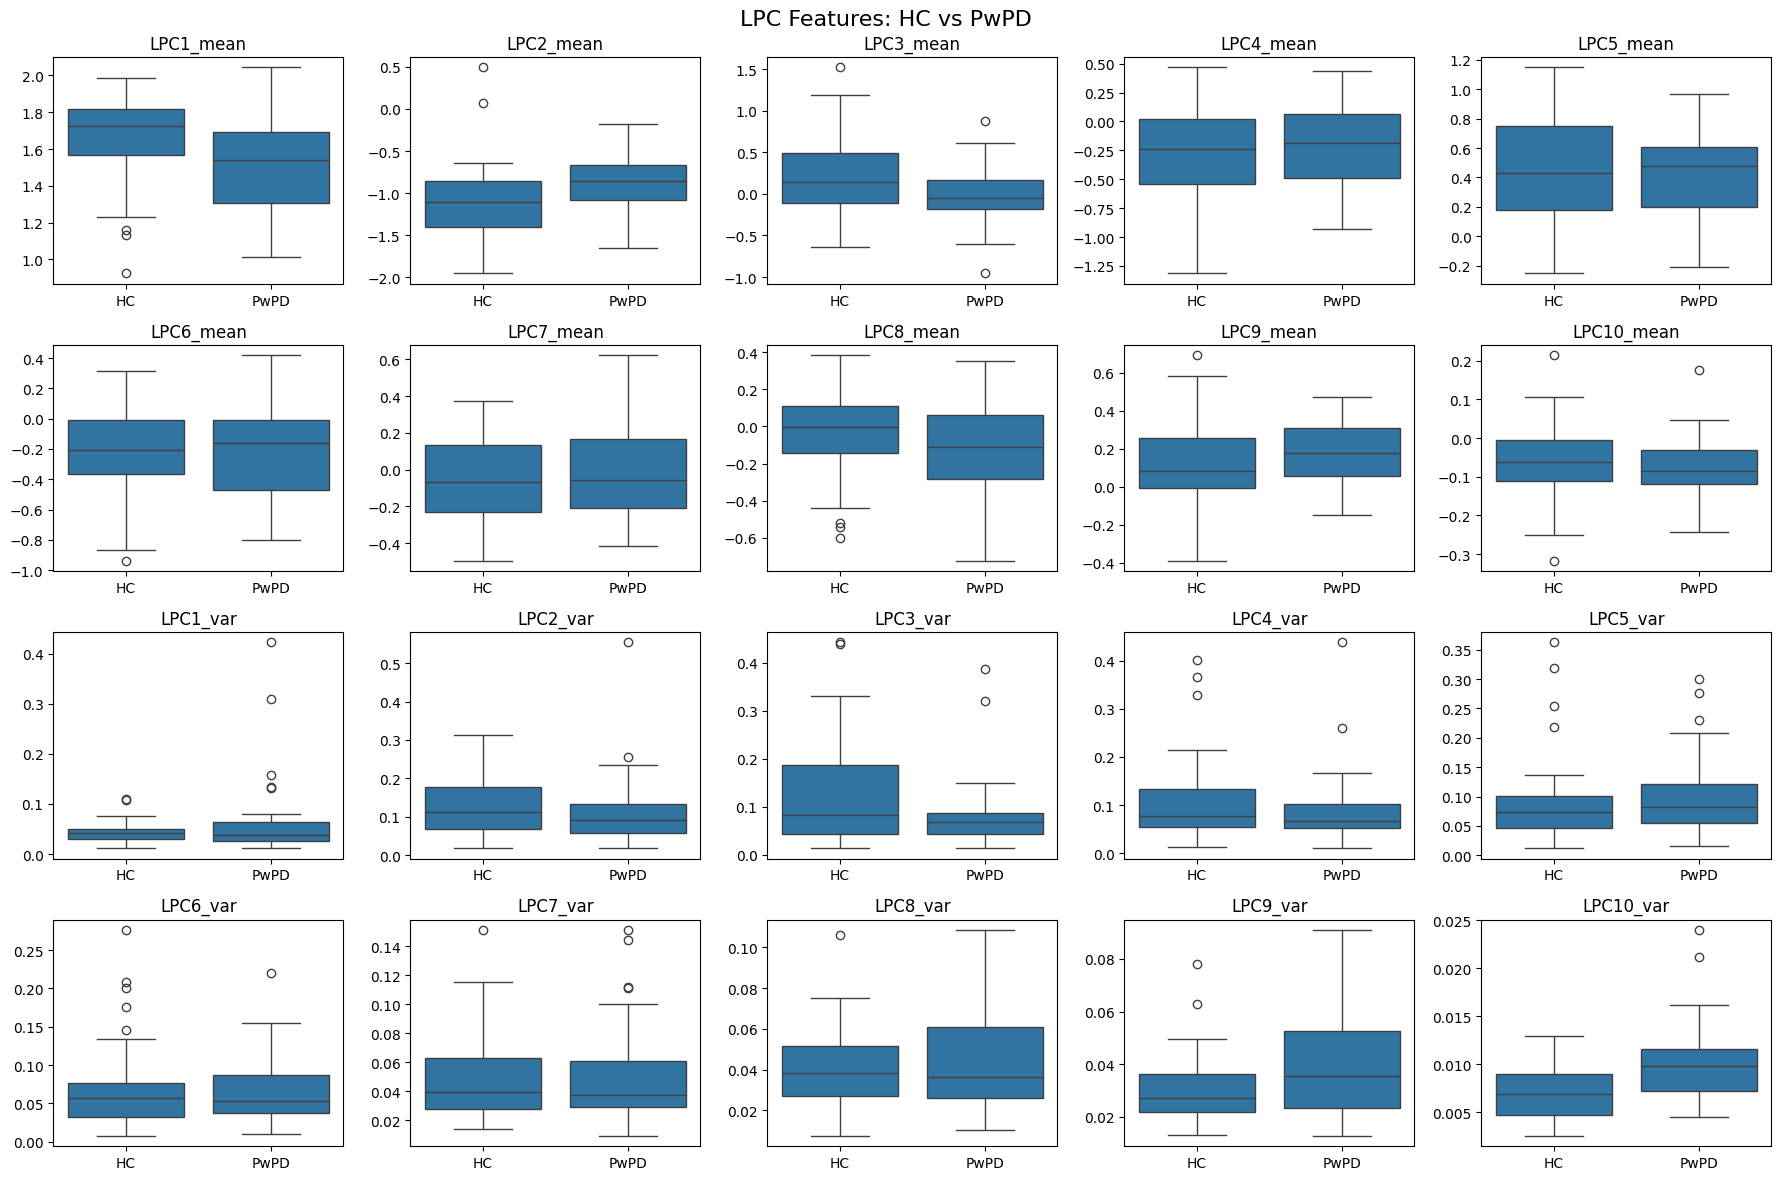

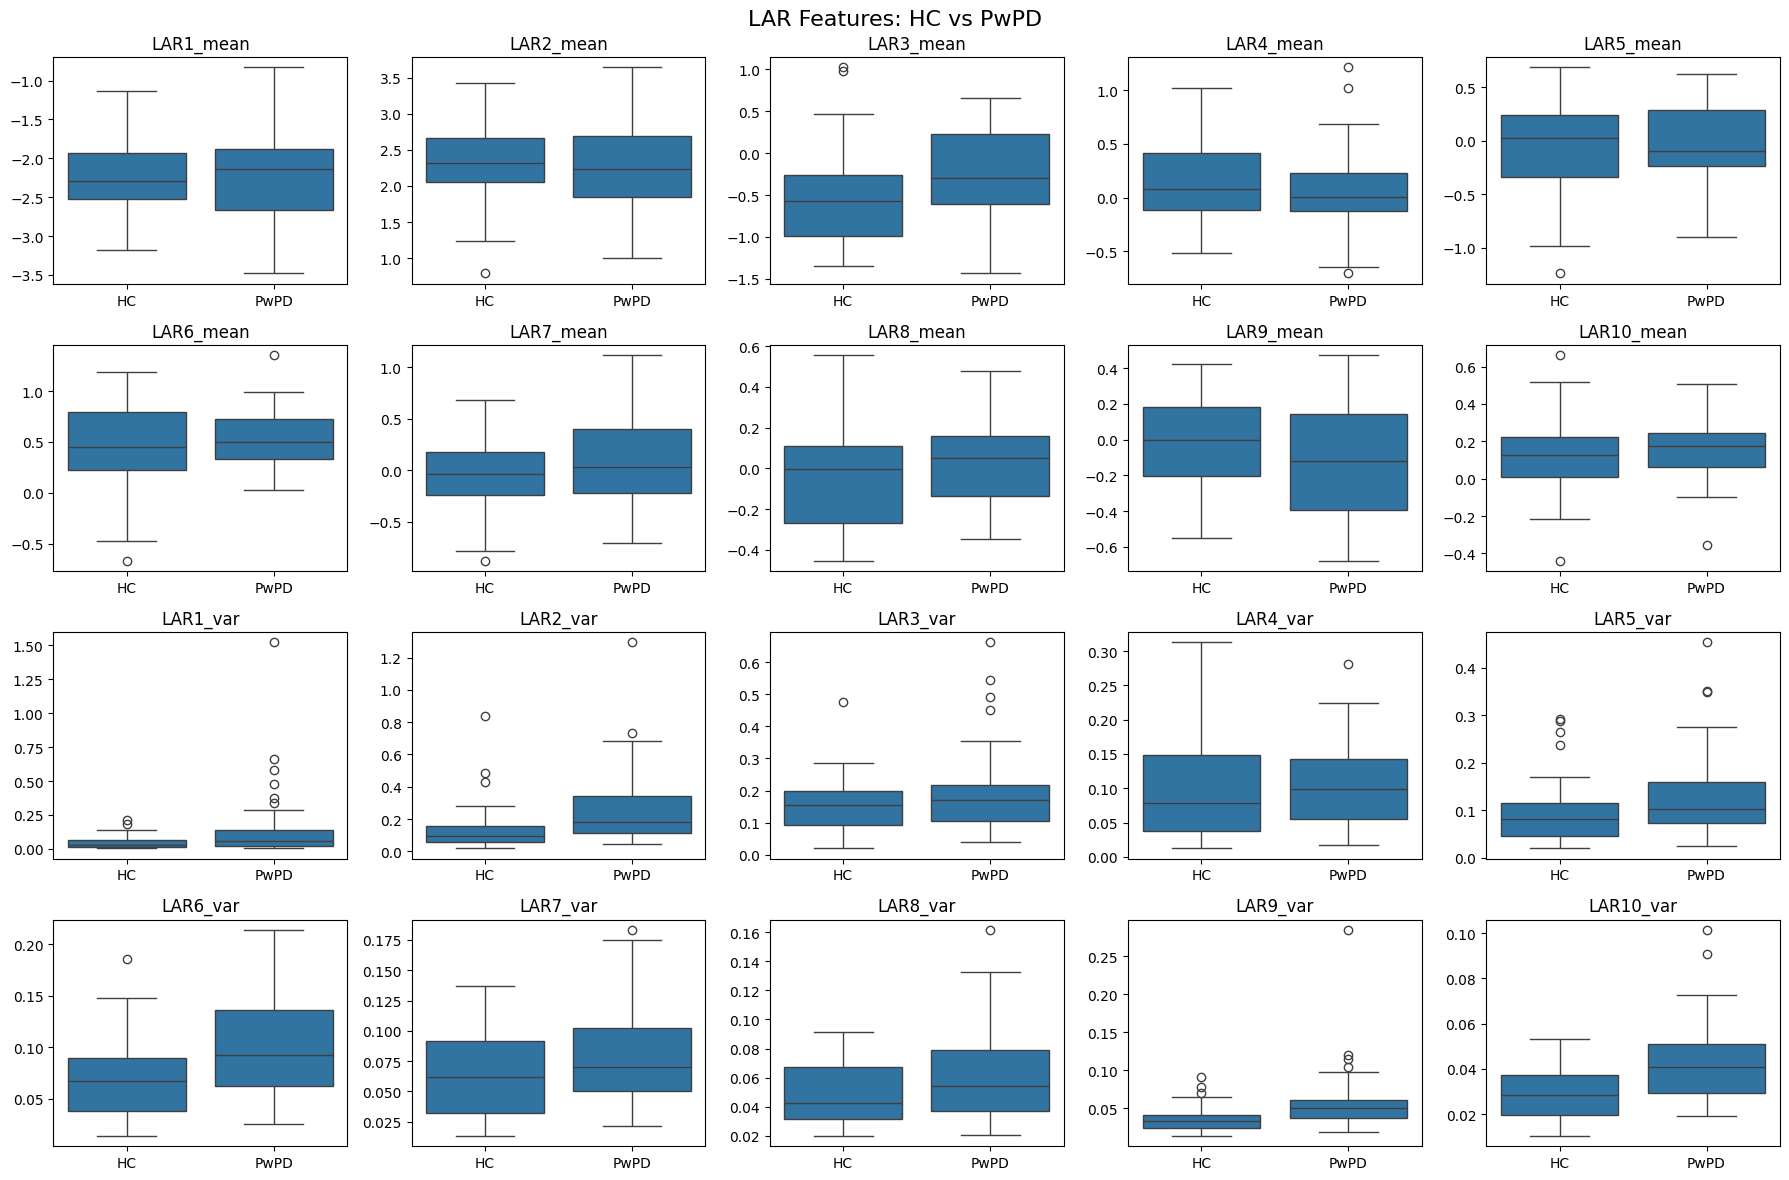

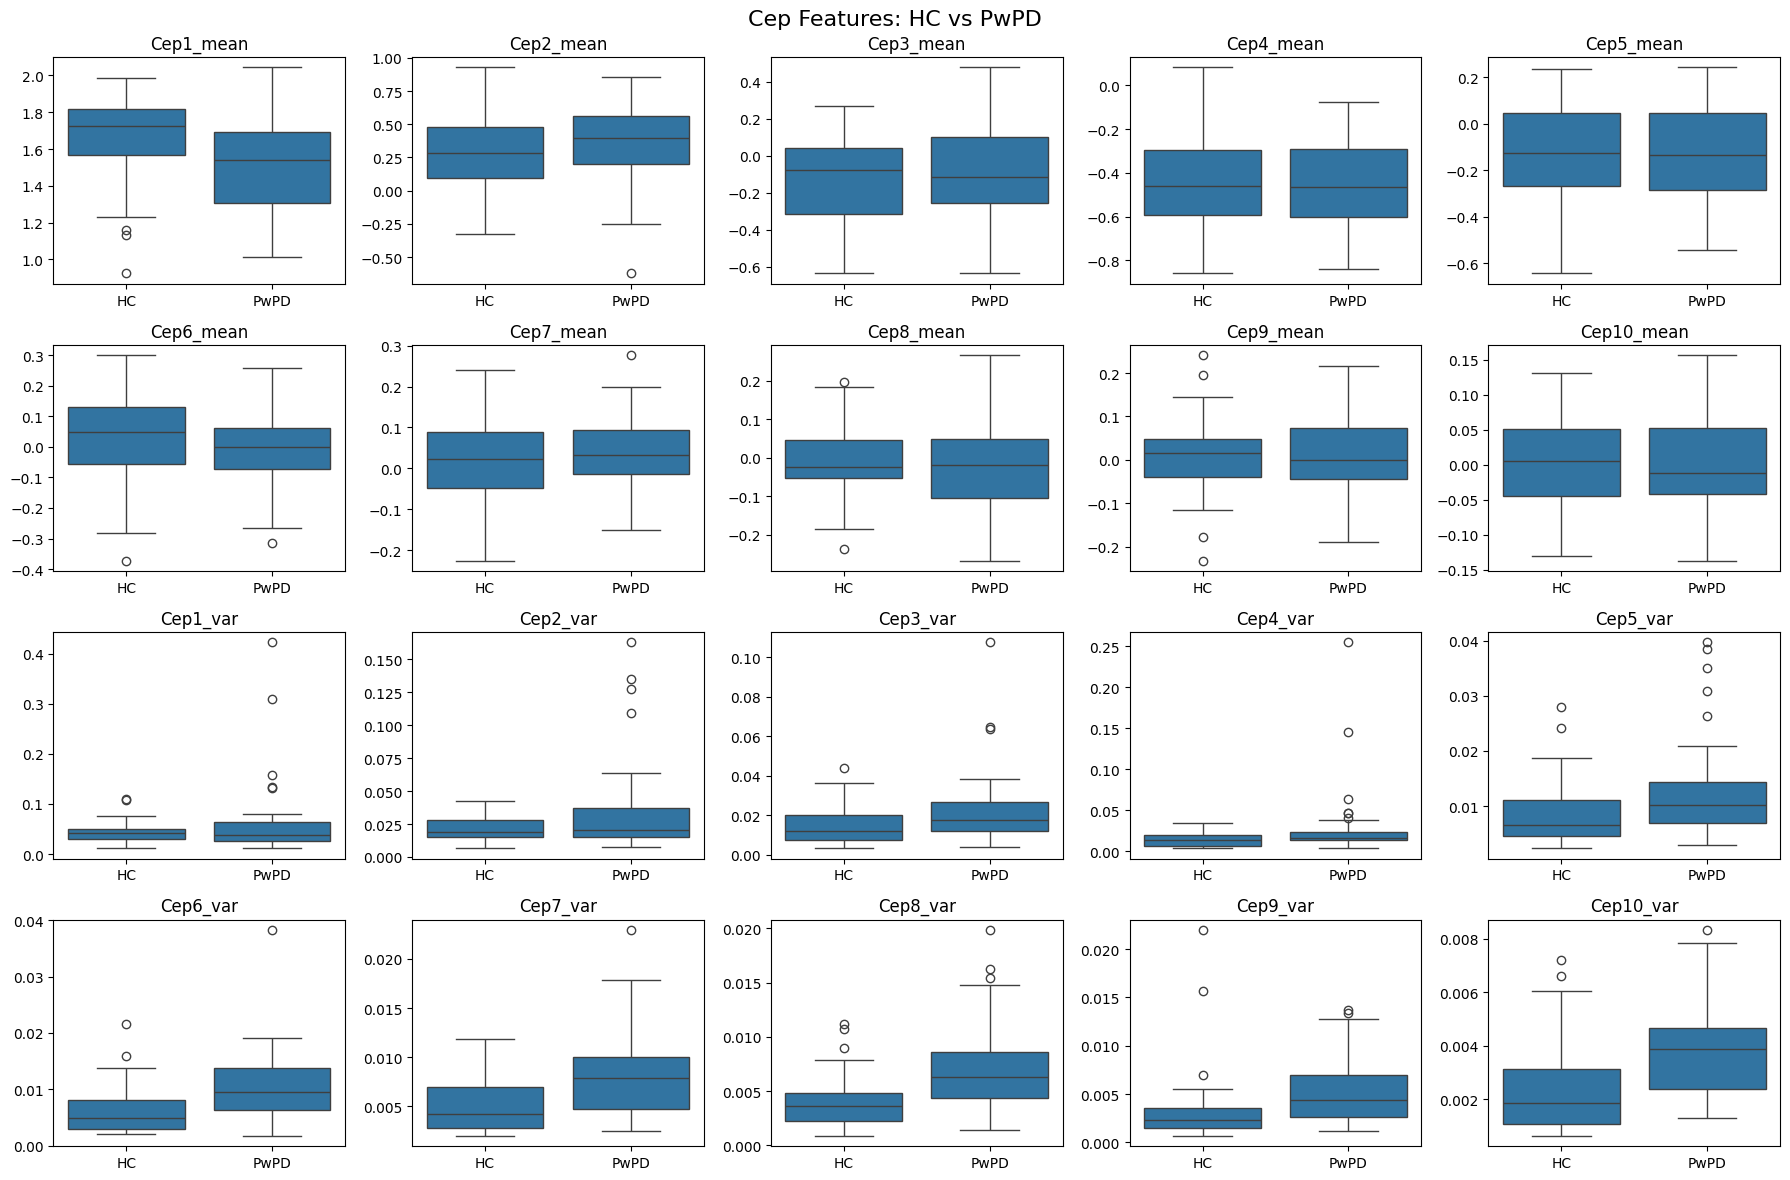

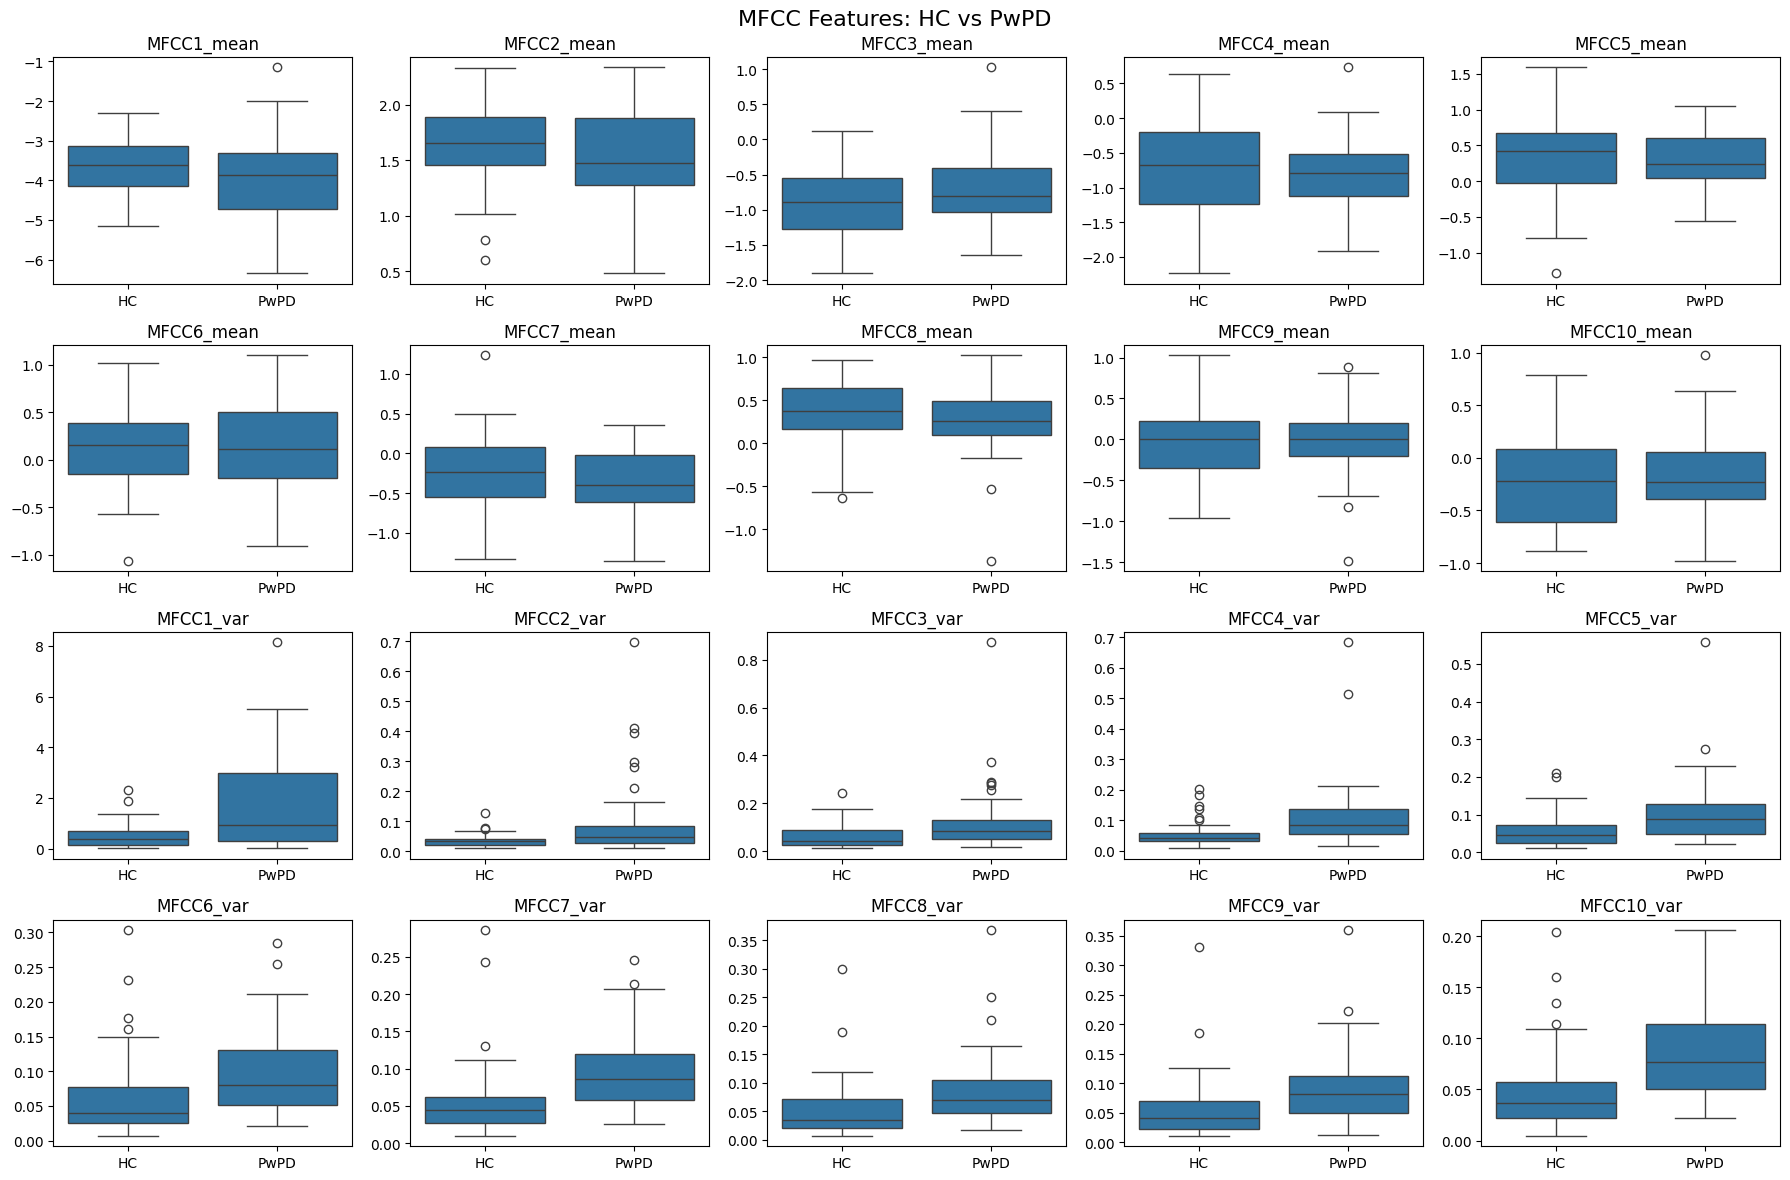

In [95]:
# Compare speech feature distributions between HC and PwPD

feature_groups = {
    "LPC": lpc_features,
    "LAR": lar_features,
    "Cep": cep_features,
    "MFCC": mfcc_features
}

for group_name, features in feature_groups.items():

    n_features = len(features)
    n_cols = 5
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(18, 3 * n_rows)
    )

    axes = axes.flatten()

    for i, feature in enumerate(features):
        sns.boxplot(
            data=master_df,
            x="Label",
            y=feature,
            ax=axes[i]
        )
        axes[i].set_title(feature)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

    # Hide unused axes
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        f"{group_name} Features: HC vs PwPD",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

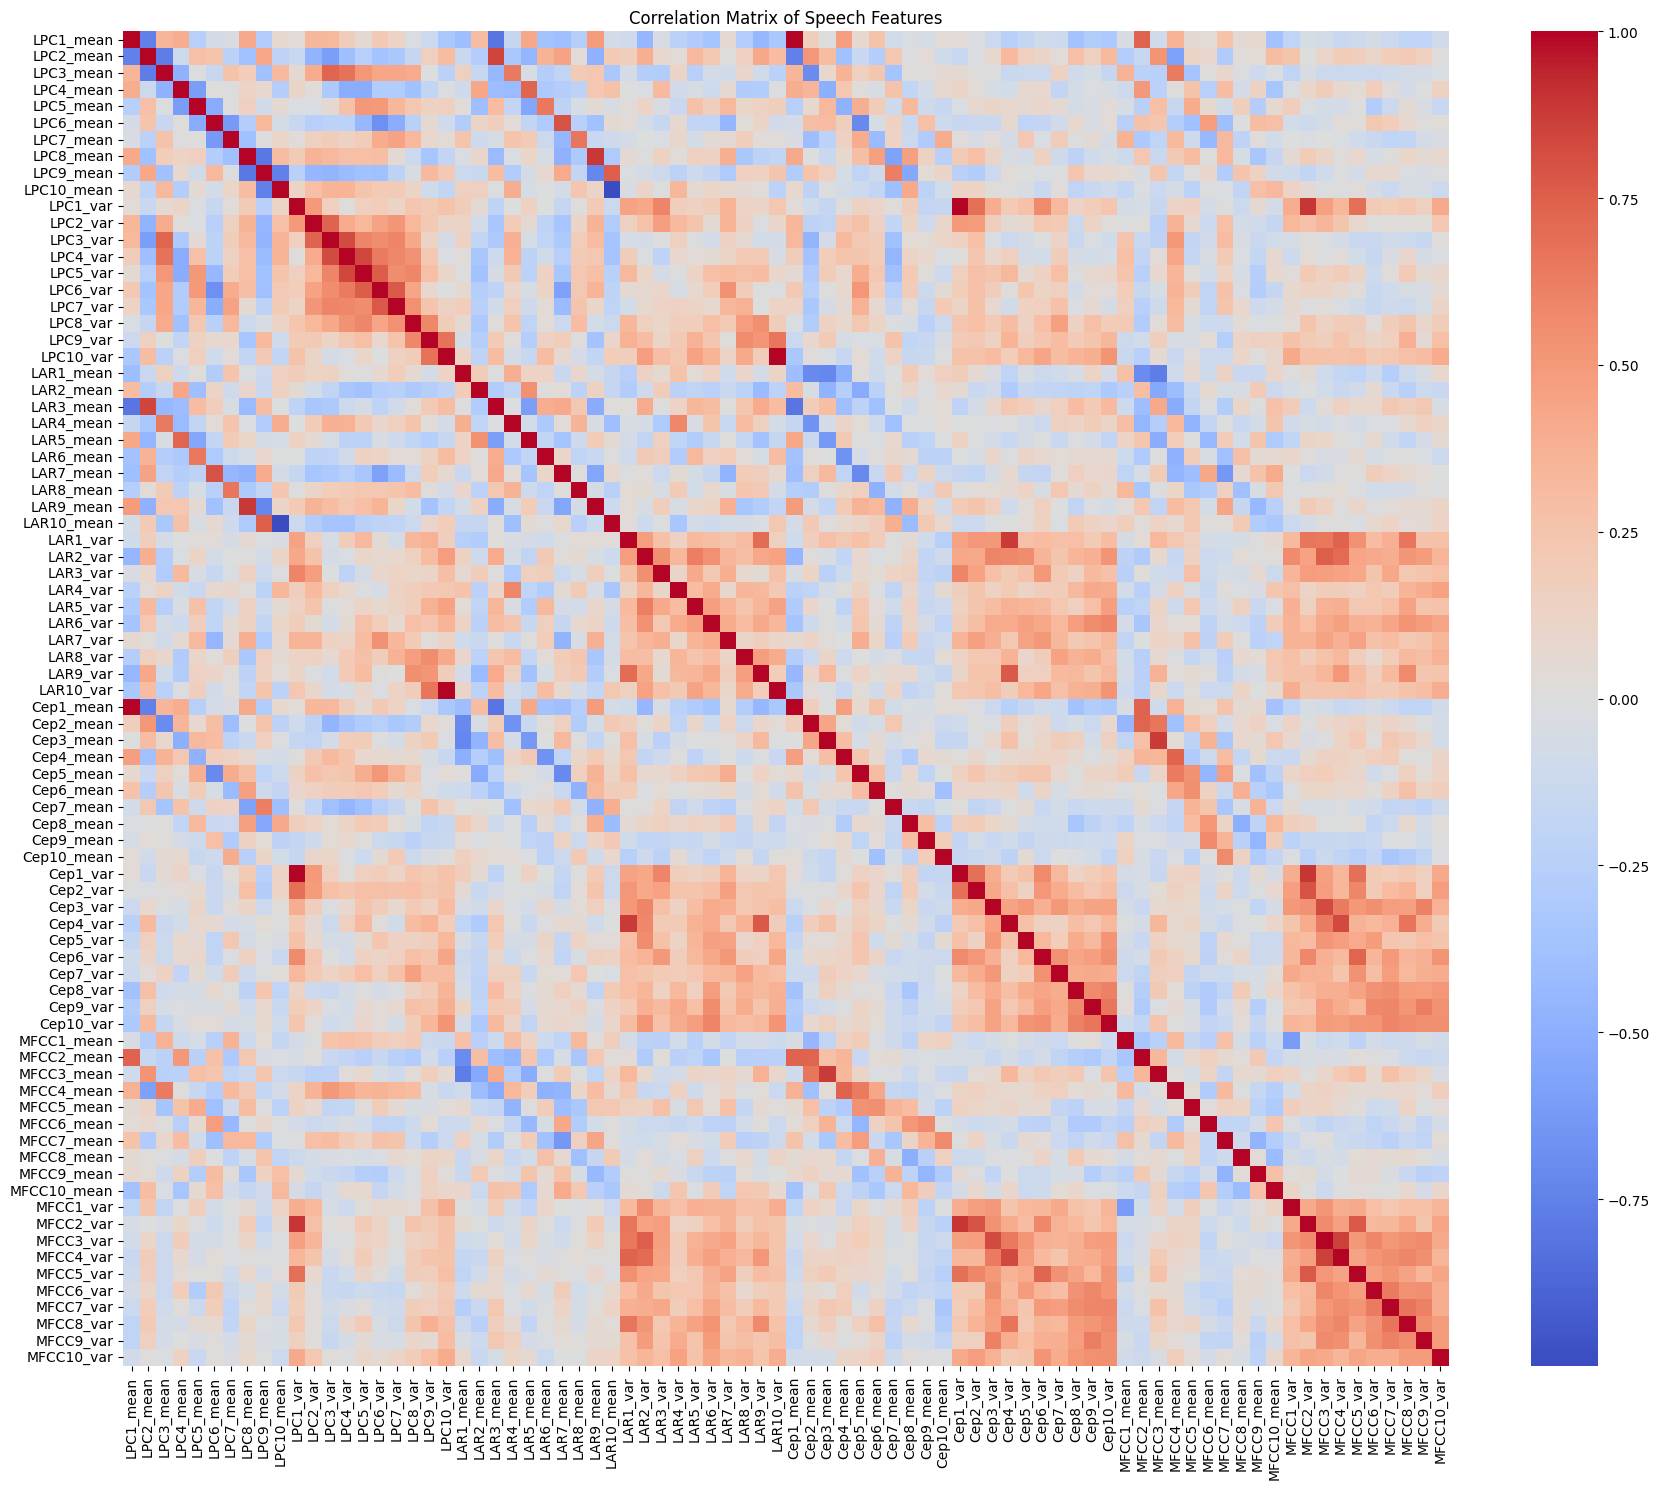

In [96]:
# Correlation matrix of speech features

corr_matrix = master_df[speech_features].corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.title("Correlation Matrix of Speech Features")
plt.tight_layout()
plt.show()

In [97]:
# Find highly correlated feature pairs

corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs = corr_pairs[abs(corr_pairs) >= 0.80]

print("Number of highly correlated feature pairs:", len(high_corr_pairs))
print(high_corr_pairs.head(20))

Number of highly correlated feature pairs: 18
LPC1_var    Cep1_var      1.000000
LPC1_mean   Cep1_mean     1.000000
LPC10_var   LAR10_var     0.996916
Cep1_var    MFCC2_var     0.893329
LPC1_var    MFCC2_var     0.893329
LPC8_mean   LAR9_mean     0.884689
Cep3_mean   MFCC3_mean    0.880762
LAR1_var    Cep4_var      0.876758
MFCC3_var   MFCC4_var     0.864845
LPC2_mean   LAR3_mean     0.844536
LPC4_var    LPC5_var      0.838697
Cep4_var    MFCC4_var     0.833416
Cep3_var    MFCC3_var     0.824725
LPC3_var    LPC4_var      0.820699
LPC6_mean   LAR7_mean     0.800884
LAR3_mean   Cep1_mean    -0.811558
LPC1_mean   LAR3_mean    -0.811558
LPC10_mean  LAR10_mean   -0.999908
dtype: float64


In [98]:
# Outlier analysis using the IQR method

outlier_summary = []

for feature in speech_features:

    Q1 = master_df[feature].quantile(0.25)
    Q3 = master_df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = master_df[
        (master_df[feature] < lower_bound) |
        (master_df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(master_df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df = outlier_df.sort_values(
    "Outlier_Count",
    ascending=False
)

outlier_df.head(20)

,Feature,Outlier_Count,Outlier_Percentage
70,MFCC1_var,12,14.814815
34,LAR5_var,10,12.345679
31,LAR2_var,9,11.111111
71,MFCC2_var,9,11.111111
51,Cep2_var,8,9.876543
12,LPC3_var,7,8.641975
10,LPC1_var,7,8.641975
14,LPC5_var,7,8.641975
58,Cep9_var,7,8.641975
30,LAR1_var,7,8.641975


In [99]:
print("Total features with at least one outlier:",
      (outlier_df["Outlier_Count"] > 0).sum())

print("\nFeatures with most outliers:")
print(outlier_df.head(10))

Total features with at least one outlier: 62

Features with most outliers:
      Feature  Outlier_Count  Outlier_Percentage
70  MFCC1_var             12           14.814815
34   LAR5_var             10           12.345679
31   LAR2_var              9           11.111111
71  MFCC2_var              9           11.111111
51   Cep2_var              8            9.876543
12   LPC3_var              7            8.641975
10   LPC1_var              7            8.641975
14   LPC5_var              7            8.641975
58   Cep9_var              7            8.641975
30   LAR1_var              7            8.641975


In [100]:
from scipy.stats import mannwhitneyu

# Statistical comparison: HC vs PwPD

hc = master_df[master_df["Label"] == "HC"]
pd_group = master_df[master_df["Label"] == "PwPD"]

test_results = []

for feature in speech_features:

    hc_values = hc[feature]
    pd_values = pd_group[feature]

    statistic, p_value = mannwhitneyu(
        hc_values,
        pd_values,
        alternative="two-sided"
    )

    test_results.append({
        "Feature": feature,
        "U_statistic": statistic,
        "p_value": p_value
    })

test_results_df = pd.DataFrame(test_results)

# Sort by p-value
test_results_df = test_results_df.sort_values("p_value")

test_results_df.head(20)

,Feature,U_statistic,p_value
57,Cep8_var,371.0,0.000023
79,MFCC10_var,372.0,0.000024
73,MFCC4_var,405.0,0.000090
59,Cep10_var,406.0,0.000094
55,Cep6_var,420.0,0.000161
31,LAR2_var,423.0,0.000180
56,Cep7_var,425.0,0.000194
76,MFCC7_var,428.0,0.000217
38,LAR9_var,435.0,0.000281
19,LPC10_var,444.0,0.000390


In [101]:
# Features with statistically significant group differences

significant_features = test_results_df[
    test_results_df["p_value"] < 0.05
]

print("Significant features (p < 0.05):",
      len(significant_features))

significant_features

Significant features (p < 0.05): 29


,Feature,U_statistic,p_value
57,Cep8_var,371.0,0.000023
79,MFCC10_var,372.0,0.000024
73,MFCC4_var,405.0,0.000090
59,Cep10_var,406.0,0.000094
55,Cep6_var,420.0,0.000161
31,LAR2_var,423.0,0.000180
56,Cep7_var,425.0,0.000194
76,MFCC7_var,428.0,0.000217
38,LAR9_var,435.0,0.000281
19,LPC10_var,444.0,0.000390


In [102]:
#Prepare X and y for Classification

# X = 80 speech-related features
X = master_df[speech_features].copy()

# y = target variable
# HC  -> 0
# PwPD -> 1
y = master_df["Label"].map({
    "HC": 0,
    "PwPD": 1
})

# Verify the data

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nFeature data types:")
print(X.dtypes.value_counts())

print("\nMissing values in X:", X.isna().sum().sum())

print("Infinite values in X:", np.isinf(X.to_numpy()).sum())

print("\nFirst 5 rows of X:")
display(X.head())

print("\nFirst 5 values of y:")
display(y.head())

X shape: (81, 80)
y shape: (81,)

Class distribution:
Label
0    41
1    40
Name: count, dtype: int64

Feature data types:
float64    80
Name: count, dtype: int64

Missing values in X: 0
Infinite values in X: 0

First 5 rows of X:


,LPC1_mean,LPC2_mean,LPC3_mean,LPC4_mean,LPC5_mean,LPC6_mean,LPC7_mean,LPC8_mean,LPC9_mean,LPC10_mean,...,MFCC1_var,MFCC2_var,MFCC3_var,MFCC4_var,MFCC5_var,MFCC6_var,MFCC7_var,MFCC8_var,MFCC9_var,MFCC10_var
0,1.569877,-0.983969,-0.091904,0.041568,0.191788,-0.288774,0.322170,-0.598547,0.407556,-0.107863,...,0.038758,0.022063,0.017446,0.040128,0.025198,0.075028,0.026978,0.022016,0.049959,0.016487
1,1.941508,-1.604020,0.596933,-0.203145,0.049751,0.149339,-0.181571,-0.076214,0.181712,-0.080028,...,0.376447,0.043026,0.113414,0.202135,0.076834,0.177133,0.106460,0.058875,0.070278,0.057396
2,1.939210,-1.400189,0.267341,-0.117478,0.393466,-0.146857,-0.267388,0.218443,0.052065,-0.110188,...,0.181835,0.065868,0.081565,0.028965,0.032045,0.029428,0.045059,0.037183,0.020112,0.016252
3,1.742062,-1.111498,0.209142,-0.208665,0.172042,0.230845,-0.125670,-0.521256,0.695029,-0.249518,...,0.101589,0.012878,0.019212,0.015828,0.023448,0.048831,0.026585,0.024423,0.011855,0.016314
4,1.370398,-0.725562,0.058470,-0.669424,0.762271,-0.077152,-0.350492,-0.027547,0.154888,-0.025133,...,0.505912,0.031619,0.023236,0.051445,0.032242,0.031627,0.053048,0.027289,0.119403,0.046914



First 5 values of y:


0    0
1    0
2    0
3    0
4    0
Name: Label, dtype: int64

In [103]:
#Scaling + Stratified 5-Fold CV + SVM

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# 1. Create the ML pipeline

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# 2. Create Stratified 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Generate out-of-fold predictions

y_pred = cross_val_predict(
    svm_pipeline,
    X,
    y,
    cv=cv,
    method="predict"
)

# Probability of PwPD (class = 1)
y_prob = cross_val_predict(
    svm_pipeline,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Cross-validation completed!")

print("\nActual labels:")
print(y.values)

print("\nPredicted labels:")
print(y_pred)

print("\nPredicted probabilities:")
print(y_prob)

Cross-validation completed!

Actual labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0]

Predicted labels:
[0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 0 0 1 0 0 1 0 0 0 1 1 1 1 1 0 0 0 0 1 0 1 0
 1 1 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 0 1 0 1 0 0 0 1 0 0 0 1 1
 0 1 0 0 0 1 0]

Predicted probabilities:
[0.47124646 0.45095392 0.33615257 0.44705187 0.39428643 0.49495082
 0.38984869 0.64490573 0.55753843 0.44189918 0.29394466 0.33413675
 0.62663205 0.73610079 0.60460455 0.38257383 0.27850321 0.62559471
 0.48942412 0.31646069 0.621534   0.4616017  0.31582843 0.38769124
 0.5812974  0.52527597 0.60832629 0.53903841 0.63567044 0.43261485
 0.48028812 0.38129836 0.41816829 0.71145401 0.43632138 0.67344667
 0.42872449 0.55110393 0.56896414 0.65486517 0.39678131 0.50858675
 0.75070101 0.74803048 0.5335037  0.34251286 0.52261806 0.60700413
 0.38713053 0.66619994 0.35232299 0.5868061

Confusion Matrix:
[[28 13]
 [15 25]]

TN: 28
FP: 13
FN: 15
TP: 25

========== SVM RESULTS ==========
Accuracy    : 0.6543
Precision   : 0.6579
Sensitivity : 0.6250
Specificity : 0.6829
F1-Score    : 0.6410
ROC-AUC     : 0.6732

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

          HC       0.65      0.68      0.67        41
        PwPD       0.66      0.62      0.64        40

    accuracy                           0.65        81
   macro avg       0.65      0.65      0.65        81
weighted avg       0.65      0.65      0.65        81



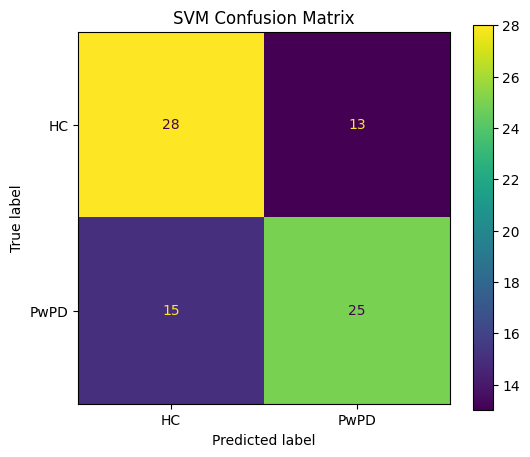

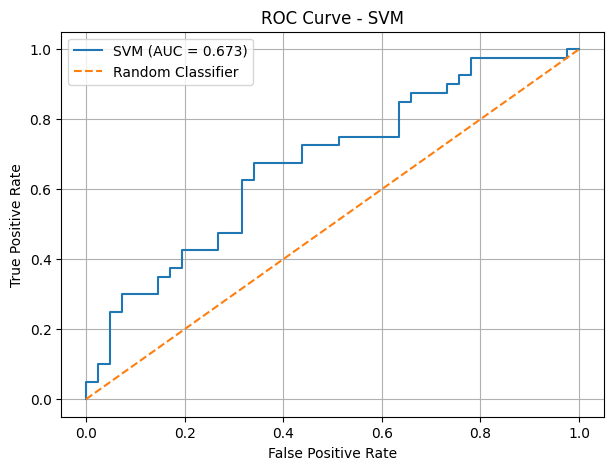

In [104]:
# STEP 3: Evaluate SVM Model

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# 1. Confusion Matrix

cm = confusion_matrix(y, y_pred)

TN, FP, FN, TP = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nTN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)


# 2. Calculate Evaluation Metrics

accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
specificity = TN / (TN + FP)
f1 = f1_score(y, y_pred)
roc_auc = roc_auc_score(y, y_prob)


# 3. Display Results

print("\n========== SVM RESULTS ==========")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Sensitivity : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-Score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")


# 4. Classification Report

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y,
        y_pred,
        target_names=["HC", "PwPD"]
    )
)


# 5. Plot Confusion Matrix

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["HC", "PwPD"]
).plot(ax=ax)

ax.set_title("SVM Confusion Matrix")

plt.show()


# 6. ROC Curve

fpr, tpr, thresholds = roc_curve(y, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.grid()

plt.show()

## Feature Transformation and Engineering

The speech feature distributions are examined to identify skewness
and determine whether transformation is appropriate before further
classification experiments.

In [105]:
# Feature Skewness Analysis

from scipy.stats import skew
import pandas as pd
import numpy as np

# Calculate skewness for every speech feature
skewness_values = X.apply(skew)

skewness_df = pd.DataFrame({
    "Feature": skewness_values.index,
    "Skewness": skewness_values.values,
    "Absolute_Skewness": np.abs(skewness_values.values)
})

skewness_df = skewness_df.sort_values(
    "Absolute_Skewness",
    ascending=False
).reset_index(drop=True)

display(skewness_df)

print(
    "\nFeatures with |skewness| > 1:",
    (skewness_df["Absolute_Skewness"] > 1).sum()
)

print(
    "Features with |skewness| > 2:",
    (skewness_df["Absolute_Skewness"] > 2).sum()
)

,Feature,Skewness,Absolute_Skewness
0,Cep4_var,5.752928,5.752928
1,LAR1_var,4.989735,4.989735
2,LPC1_var,4.516065,4.516065
3,Cep1_var,4.516065,4.516065
4,MFCC3_var,4.264719,4.264719
...,...,...,...
75,Cep9_mean,0.048871,0.048871
76,LPC9_mean,0.031741,0.031741
77,Cep10_mean,0.013218,0.013218
78,MFCC4_mean,0.009097,0.009097



Features with |skewness| > 1: 37
Features with |skewness| > 2: 17


In [106]:
# Yeo-Johnson Transformation

from sklearn.preprocessing import PowerTransformer

# Create Yeo-Johnson transformer
yj_transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

# Apply transformation for analysis
X_yj_array = yj_transformer.fit_transform(X)

# Convert transformed data back to DataFrame
X_yj = pd.DataFrame(
    X_yj_array,
    columns=X.columns,
    index=X.index
)

print("Original shape   :", X.shape)
print("Transformed shape:", X_yj.shape)
print("\nYeo-Johnson transformation completed.")

Original shape   : (81, 80)
Transformed shape: (81, 80)

Yeo-Johnson transformation completed.


In [107]:
# Compare Skewness Before vs After

original_skewness = X.apply(skew)
transformed_skewness = X_yj.apply(skew)

transformation_comparison = pd.DataFrame({
    "Feature": X.columns,
    "Original_Skewness": original_skewness.values,
    "Transformed_Skewness": transformed_skewness.values
})

transformation_comparison["Original_Abs_Skewness"] = (
    transformation_comparison["Original_Skewness"].abs()
)

transformation_comparison["Transformed_Abs_Skewness"] = (
    transformation_comparison["Transformed_Skewness"].abs()
)

transformation_comparison["Reduction_in_Abs_Skewness"] = (
    transformation_comparison["Original_Abs_Skewness"]
    - transformation_comparison["Transformed_Abs_Skewness"]
)

transformation_comparison = transformation_comparison.sort_values(
    "Original_Abs_Skewness",
    ascending=False
)

display(transformation_comparison.head(20))

,Feature,Original_Skewness,Transformed_Skewness,Original_Abs_Skewness,Transformed_Abs_Skewness,Reduction_in_Abs_Skewness
53,Cep4_var,5.752928,0.440697,5.752928,0.440697,5.312231
30,LAR1_var,4.989735,0.640982,4.989735,0.640982,4.348752
10,LPC1_var,4.516065,0.364227,4.516065,0.364227,4.151837
50,Cep1_var,4.516065,0.364227,4.516065,0.364227,4.151837
72,MFCC3_var,4.264719,0.350867,4.264719,0.350867,3.913853
38,LAR9_var,4.158408,0.192094,4.158408,0.192094,3.966314
73,MFCC4_var,4.048183,0.313792,4.048183,0.313792,3.734391
71,MFCC2_var,3.960659,0.713762,3.960659,0.713762,3.246896
51,Cep2_var,3.060238,0.393943,3.060238,0.393943,2.666295
52,Cep3_var,2.988522,0.242383,2.988522,0.242383,2.746139


In [108]:
print(
    "Features with |skewness| > 1 BEFORE:",
    (original_skewness.abs() > 1).sum()
)

print(
    "Features with |skewness| > 1 AFTER:",
    (transformed_skewness.abs() > 1).sum()
)

print(
    "Features with |skewness| > 2 BEFORE:",
    (original_skewness.abs() > 2).sum()
)

print(
    "Features with |skewness| > 2 AFTER:",
    (transformed_skewness.abs() > 2).sum()
)

Features with |skewness| > 1 BEFORE: 37
Features with |skewness| > 1 AFTER: 0
Features with |skewness| > 2 BEFORE: 17
Features with |skewness| > 2 AFTER: 0


During feature analysis, we found that 37 out of 80 speech features had absolute skewness greater than 1, and 17 had absolute skewness greater than 2. We therefore investigated Yeo-Johnson transformation. After transformation, none of the 80 features had absolute skewness greater than 1.

In [109]:
# Yeo-Johnson + SVM Classification

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [110]:
# Yeo-Johnson + StandardScaler + SVM

yj_svm_pipeline = Pipeline([
    (
        "yeo_johnson",
        PowerTransformer(
            method="yeo-johnson",
            standardize=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        )
    )
])

In [111]:
# Stratified 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [112]:
# Generate predictions

y_pred_yj = cross_val_predict(
    yj_svm_pipeline,
    X,
    y,
    cv=cv,
    method="predict"
)

y_prob_yj = cross_val_predict(
    yj_svm_pipeline,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Yeo-Johnson + SVM cross-validation completed.")

Yeo-Johnson + SVM cross-validation completed.


In [113]:
# Evaluate Yeo-Johnson + SVM

cm_yj = confusion_matrix(y, y_pred_yj)

TN_yj, FP_yj, FN_yj, TP_yj = cm_yj.ravel()

accuracy_yj = accuracy_score(y, y_pred_yj)

precision_yj = precision_score(y, y_pred_yj)

recall_yj = recall_score(y, y_pred_yj)

specificity_yj = TN_yj / (TN_yj + FP_yj)

f1_yj = f1_score(y, y_pred_yj)

roc_auc_yj = roc_auc_score(y, y_prob_yj)


print("\n YEO-JOHNSON + SVM ")

print(f"Accuracy    : {accuracy_yj:.4f}")
print(f"Precision   : {precision_yj:.4f}")
print(f"Sensitivity : {recall_yj:.4f}")
print(f"Specificity : {specificity_yj:.4f}")
print(f"F1-Score    : {f1_yj:.4f}")
print(f"ROC-AUC     : {roc_auc_yj:.4f}")

print("\nConfusion Matrix:")
print(cm_yj)


 YEO-JOHNSON + SVM 
Accuracy    : 0.6667
Precision   : 0.6667
Sensitivity : 0.6500
Specificity : 0.6829
F1-Score    : 0.6582
ROC-AUC     : 0.7287

Confusion Matrix:
[[28 13]
 [14 26]]


In [114]:
# Compare Baseline vs Transformed SVM

comparison_results = pd.DataFrame({
    "Experiment": [
        "Baseline SVM",
        "Yeo-Johnson + SVM"
    ],
    
    "Accuracy": [
        accuracy,
        accuracy_yj
    ],
    
    "Precision": [
        precision,
        precision_yj
    ],
    
    "Sensitivity": [
        recall,
        recall_yj
    ],
    
    "Specificity": [
        specificity,
        specificity_yj
    ],
    
    "F1-Score": [
        f1,
        f1_yj
    ],
    
    "ROC-AUC": [
        roc_auc,
        roc_auc_yj
    ]
})

display(comparison_results.round(4))

,Experiment,Accuracy,Precision,Sensitivity,Specificity,F1-Score,ROC-AUC
0,Baseline SVM,0.6543,0.6579,0.625,0.6829,0.6410,0.6732
1,Yeo-Johnson + SVM,0.6667,0.6667,0.650,0.6829,0.6582,0.7287


## Correlation-Based Feature Reduction

The correlation analysis identified highly correlated speech features,
indicating potential redundancy in the feature space. Since the dataset
contains 80 speech features for only 81 subjects, correlation-based
feature reduction is investigated to reduce redundant information before
classification.

Features with an absolute pairwise correlation above 0.90 are considered
highly correlated. One feature from each redundant pair is removed.

In [115]:
# STEP 7: Correlation-Based Feature Reduction

# Calculate absolute correlation matrix
corr_matrix = X.corr().abs()

# Keep only the upper triangle
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Identify features having correlation > 0.90
correlation_threshold = 0.90

features_to_remove = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > correlation_threshold)
]

# Create reduced feature list
reduced_features = [
    feature
    for feature in X.columns
    if feature not in features_to_remove
]

print("Original number of features :", len(X.columns))
print("Correlation threshold       :", correlation_threshold)
print("Features removed            :", len(features_to_remove))
print("Remaining features          :", len(reduced_features))

print("\nRemoved features:")
print(features_to_remove)

print("\nRemaining features:")
print(reduced_features)

Original number of features : 80
Correlation threshold       : 0.9
Features removed            : 4
Remaining features          : 76

Removed features:
['LAR10_mean', 'LAR10_var', 'Cep1_mean', 'Cep1_var']

Remaining features:
['LPC1_mean', 'LPC2_mean', 'LPC3_mean', 'LPC4_mean', 'LPC5_mean', 'LPC6_mean', 'LPC7_mean', 'LPC8_mean', 'LPC9_mean', 'LPC10_mean', 'LPC1_var', 'LPC2_var', 'LPC3_var', 'LPC4_var', 'LPC5_var', 'LPC6_var', 'LPC7_var', 'LPC8_var', 'LPC9_var', 'LPC10_var', 'LAR1_mean', 'LAR2_mean', 'LAR3_mean', 'LAR4_mean', 'LAR5_mean', 'LAR6_mean', 'LAR7_mean', 'LAR8_mean', 'LAR9_mean', 'LAR1_var', 'LAR2_var', 'LAR3_var', 'LAR4_var', 'LAR5_var', 'LAR6_var', 'LAR7_var', 'LAR8_var', 'LAR9_var', 'Cep2_mean', 'Cep3_mean', 'Cep4_mean', 'Cep5_mean', 'Cep6_mean', 'Cep7_mean', 'Cep8_mean', 'Cep9_mean', 'Cep10_mean', 'Cep2_var', 'Cep3_var', 'Cep4_var', 'Cep5_var', 'Cep6_var', 'Cep7_var', 'Cep8_var', 'Cep9_var', 'Cep10_var', 'MFCC1_mean', 'MFCC2_mean', 'MFCC3_mean', 'MFCC4_mean', 'MFCC5_mean', 

In [116]:
# Create Reduced Feature Matrix

X_reduced = master_df[reduced_features].copy()

print("Original X shape :", X.shape)
print("Reduced X shape  :", X_reduced.shape)

Original X shape : (81, 80)
Reduced X shape  : (81, 76)


In [117]:
# Correlation-Reduced Features + Yeo-Johnson + SVM

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Use correlation-reduced feature set
X_corr = X_reduced.copy()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

corr_yj_svm_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Cross-validated predictions
y_pred_corr = cross_val_predict(
    corr_yj_svm_pipeline,
    X_corr,
    y,
    cv=cv,
    method="predict"
)

# Cross-validated probabilities
y_prob_corr = cross_val_predict(
    corr_yj_svm_pipeline,
    X_corr,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Evaluation
accuracy_corr = accuracy_score(y, y_pred_corr)
precision_corr = precision_score(y, y_pred_corr)
sensitivity_corr = recall_score(y, y_pred_corr)
f1_corr = f1_score(y, y_pred_corr)
roc_auc_corr = roc_auc_score(y, y_prob_corr)

cm_corr = confusion_matrix(y, y_pred_corr)

print("Correlation-Reduced + Yeo-Johnson + SVM")
print("-" * 50)
print(f"Accuracy    : {accuracy_corr:.4f}")
print(f"Precision   : {precision_corr:.4f}")
print(f"Sensitivity : {sensitivity_corr:.4f}")
print(f"F1 Score    : {f1_corr:.4f}")
print(f"ROC-AUC     : {roc_auc_corr:.4f}")

print("\nConfusion Matrix:")
print(cm_corr)

Correlation-Reduced + Yeo-Johnson + SVM
--------------------------------------------------
Accuracy    : 0.6543
Precision   : 0.6579
Sensitivity : 0.6250
F1 Score    : 0.6410
ROC-AUC     : 0.7341

Confusion Matrix:
[[28 13]
 [15 25]]


In [118]:
# Compare all SVM experiments

comparison = pd.DataFrame({
    "Experiment": [
        "Raw Features + SVM",
        "Yeo-Johnson + SVM",
        "Correlation Reduction + Yeo-Johnson + SVM"
    ],
    "Features": [
        80,
        80,
        76
    ],
    "Accuracy": [
        0.6543,
        0.6667,
        accuracy_corr
    ],
    "Sensitivity": [
        0.6250,
        0.6500,
        sensitivity_corr
    ],
    "F1 Score": [
        0.6410,
        0.6582,
        f1_corr
    ],
    "ROC-AUC": [
        0.6732,
        0.7287,
        roc_auc_corr
    ]
})

comparison

,Experiment,Features,Accuracy,Sensitivity,F1 Score,ROC-AUC
0,Raw Features + SVM,80,0.654300,0.625,0.641000,0.673200
1,Yeo-Johnson + SVM,80,0.666700,0.650,0.658200,0.728700
2,Correlation Reduction + Yeo-Johnson + SVM,76,0.654321,0.625,0.641026,0.734146


### Observation

Correlation-based feature reduction from 80 to 76 features did not improve
the classification performance of the SVM model.

Compared with the Yeo-Johnson + SVM model, accuracy decreased from 66.67%
to 65.43%, while sensitivity decreased from 65.00% to 62.50% and F1-score
decreased from 65.82% to 64.10%.

However, ROC-AUC increased slightly from 72.87% to 73.41%, indicating a
small improvement in the model's ability to discriminate between the two
classes across classification thresholds.

Therefore, correlation-based removal of highly redundant features does not
provide a clear benefit for the current SVM classifier. The 80-feature
Yeo-Johnson pipeline is retained as the stronger SVM configuration for
subsequent experiments.

## Supervised Feature Selection

Correlation analysis evaluates redundancy between features, but it does not
directly determine which features are most useful for Parkinson's disease
classification.

Therefore, supervised feature selection is investigated using SelectKBest.
Different numbers of selected features are evaluated within the cross-validation
pipeline to determine whether a smaller predictive feature subset can improve
generalization.

Feature selection is performed separately within each cross-validation fold to
avoid data leakage.

In [ ]:
# Supervised Feature Selection with SelectKBest

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

k_values = [10, 20, 30, 40, 60, 80]

feature_selection_results = []

for k in k_values:

    pipeline = Pipeline([
        ("yeo_johnson", PowerTransformer(
            method="yeo-johnson",
            standardize=False
        )),
        
        ("feature_selection", SelectKBest(
            score_func=f_classif,
            k=k
        )),
        
        ("scaler", StandardScaler()),
        
        ("svm", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])

    y_pred_k = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict"
    )

    y_prob_k = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    feature_selection_results.append({
        "K": k,
        "Accuracy": accuracy_score(y, y_pred_k),
        "Precision": precision_score(y, y_pred_k),
        "Sensitivity": recall_score(y, y_pred_k),
        "F1": f1_score(y, y_pred_k),
        "ROC-AUC": roc_auc_score(y, y_prob_k)
    })

feature_selection_results = pd.DataFrame(feature_selection_results)

feature_selection_results

,K,Accuracy,Precision,Sensitivity,F1,ROC-AUC
0,10,0.666667,0.651163,0.700,0.674699,0.670732
1,20,0.691358,0.666667,0.750,0.705882,0.723476
2,30,0.716049,0.717949,0.700,0.708861,0.746341
3,40,0.691358,0.692308,0.675,0.683544,0.731098
4,60,0.679012,0.675000,0.675,0.675000,0.733841
5,80,0.666667,0.666667,0.650,0.658228,0.728659


## Model Comparison

The previous experiments showed that supervised feature selection using
SelectKBest with 30 features improved the performance of the SVM classifier.

To determine whether this improvement is specific to SVM, multiple machine
learning classifiers are compared using the same preprocessing and feature
selection strategy.

The evaluated models are:

1. Logistic Regression
2. RBF-kernel Support Vector Machine
3. Random Forest

Yeo-Johnson transformation and SelectKBest feature selection are included
inside each cross-validation pipeline to prevent data leakage.

In [120]:
# Model Comparison using 30 Selected Features

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    
    "SVM (RBF)": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

model_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("yeo_johnson", PowerTransformer(
            method="yeo-johnson",
            standardize=False
        )),
        
        ("feature_selection", SelectKBest(
            score_func=f_classif,
            k=30
        )),
        
        ("scaler", StandardScaler()),
        
        ("classifier", model)
    ])

    y_pred_model = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict"
    )

    y_prob_model = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y, y_pred_model),
        "Precision": precision_score(y, y_pred_model),
        "Sensitivity": recall_score(y, y_pred_model),
        "F1 Score": f1_score(y, y_pred_model),
        "ROC-AUC": roc_auc_score(y, y_prob_model)
    })

model_results = pd.DataFrame(model_results)

model_results

,Model,Accuracy,Precision,Sensitivity,F1 Score,ROC-AUC
0,Logistic Regression,0.617284,0.645161,0.5,0.563380,0.667073
1,SVM (RBF),0.716049,0.717949,0.7,0.708861,0.746341
2,Random Forest,0.629630,0.631579,0.6,0.615385,0.726220


### Observation

The three classifiers showed different performance when trained using the
30 features selected by SelectKBest.

The RBF-kernel SVM achieved the highest performance across all evaluated
metrics, with an accuracy of 71.60%, sensitivity of 70.00%, F1-score of
70.89%, and ROC-AUC of 74.63%.

Logistic Regression achieved lower performance, particularly in sensitivity
(50.00%), indicating that the linear classifier had difficulty identifying
the positive class in this experiment.

Random Forest achieved an accuracy of 62.96% and ROC-AUC of 72.62%. Although
its ROC-AUC was relatively close to that of SVM, its threshold-based
classification metrics were lower.

Overall, among the evaluated classifiers, the RBF-SVM provided the strongest
cross-validated performance for the selected 30-feature representation.
Therefore, SVM is selected for further investigation through hyperparameter
tuning and subsequent analysis.

## Hyperparameter Tuning of the RBF-SVM

The RBF-SVM achieved the strongest performance among the evaluated
classifiers. Therefore, hyperparameter tuning is performed to investigate
whether its performance can be improved further.

The two main RBF-SVM hyperparameters considered are:

- C: regularization parameter
- gamma: kernel coefficient controlling the influence of individual samples

Yeo-Johnson transformation and SelectKBest feature selection are kept inside
the pipeline so that all preprocessing and feature selection are performed
within the cross-validation procedure.

In [121]:
# RBF-SVM Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    
    ("feature_selection", SelectKBest(
        score_func=f_classif,
        k=30
    )),
    
    ("scaler", StandardScaler()),
    
    ("svm", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X, y)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(f"{grid_search.best_score_:.4f}")

Best Parameters:
{'svm__C': 0.1, 'svm__gamma': 0.001}

Best Cross-Validation ROC-AUC:
0.7774


In [122]:
# Evaluate the tuned SVM using cross-validated predictions

tuned_svm = grid_search.best_estimator_

y_pred_tuned = cross_val_predict(
    tuned_svm,
    X,
    y,
    cv=cv,
    method="predict"
)

y_prob_tuned = cross_val_predict(
    tuned_svm,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

tuned_accuracy = accuracy_score(y, y_pred_tuned)
tuned_precision = precision_score(y, y_pred_tuned)
tuned_sensitivity = recall_score(y, y_pred_tuned)
tuned_f1 = f1_score(y, y_pred_tuned)
tuned_roc_auc = roc_auc_score(y, y_prob_tuned)

print("Tuned RBF-SVM")
print("-" * 40)
print(f"Accuracy    : {tuned_accuracy:.4f}")
print(f"Precision   : {tuned_precision:.4f}")
print(f"Sensitivity : {tuned_sensitivity:.4f}")
print(f"F1 Score    : {tuned_f1:.4f}")
print(f"ROC-AUC     : {tuned_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred_tuned))

Tuned RBF-SVM
----------------------------------------
Accuracy    : 0.5679
Precision   : 0.8571
Sensitivity : 0.1500
F1 Score    : 0.2553
ROC-AUC     : 0.3494

Confusion Matrix:
[[40  1]
 [34  6]]
